In [1]:
import os
import pandas as pd
import numpy as np
from numpy import nan
import glob
from scipy.stats import skew
import scipy.stats
from scipy import stats
import calendar
from scipy.optimize import differential_evolution
from multiprocessing import Pool
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter
import seaborn as sns
from netCDF4 import Dataset
from scipy.stats import gumbel_r
from scipy.interpolate import interp1d

In [2]:
def simulate_storms(month_lengths, simulation_length, parameters, rng):
    simulation_end_time = np.cumsum(month_lengths)[-1]

    sim_len_ext = simulation_length + 4
    month_lengths_ext = month_lengths.copy()
    for _ in range(4):
        month_lengths_ext = np.concatenate([month_lengths_ext, month_lengths[-12:]])

    lamda = np.tile(parameters['lamda'].values, sim_len_ext)
    cumulative_expected_storms = np.cumsum(lamda * month_lengths_ext)
    cumulative_month_endtimes = np.cumsum(month_lengths_ext)
    expected_number_of_storms = cumulative_expected_storms[-1]
    number_of_storms = rng.poisson(expected_number_of_storms)

    deformed_arrivals = expected_number_of_storms * np.sort(rng.uniform(size=number_of_storms))
    cumulative_expected_storms = np.insert(cumulative_expected_storms, 0, 0.0)
    cumulative_month_endtimes = np.insert(cumulative_month_endtimes, 0, 0.0)
    interpolator = scipy.interpolate.interp1d(
        cumulative_expected_storms, cumulative_month_endtimes
    )
    storm_arrival_times = interpolator(deformed_arrivals)

    storm_arrival_times = storm_arrival_times[storm_arrival_times < simulation_end_time]
    number_of_storms = storm_arrival_times.shape[0]
    storms = pd.DataFrame({
        'storm_id': np.arange(number_of_storms),
        'storm_arrival': storm_arrival_times
    })
    storms['month'] = lookup_months(month_lengths, simulation_length, storms['storm_arrival'].values)
    return storms, number_of_storms


def lookup_months(month_lengths, period_length, times):
    end_times = np.cumsum(month_lengths)
    repeated_months = np.tile(np.arange(1, 13, dtype=int), period_length)
    idx = np.digitize(times, end_times)
    return repeated_months[idx]


def simulate_raincells_point(storms, parameters, rng):
    tmp = pd.merge(storms, parameters, how='left', on='month')
    tmp.sort_values(['storm_id'], inplace=True)

    number_of_raincells = rng.poisson(tmp['nu'].values)
    storm_ids, storm_arrivals, storm_months = make_storm_arrays_by_raincell(
        number_of_raincells,
        storms['storm_id'].values,
        storms['storm_arrival'].values,
        storms['month'].values
    )
    return pd.DataFrame({
        'storm_id': storm_ids,
        'storm_arrival': storm_arrivals,
        'month': storm_months
    })


def make_storm_arrays_by_raincell(num_cells, storm_ids, storm_arrivals, storm_months):
    return (
        np.repeat(storm_ids, num_cells),
        np.repeat(storm_arrivals, num_cells),
        np.repeat(storm_months, num_cells)
    )


def merge_parameters(df, month_lengths, simulation_length, parameters):
    df['month'] = lookup_months(month_lengths, simulation_length, df['storm_arrival'].values)
    parameters_subset = parameters.drop(
        ['fit_stage', 'converged', 'objective_function',
         'iterations', 'function_evaluations'],
        axis=1, errors='ignore'
    )
    return pd.merge(df, parameters_subset, how='left', on='month')


def main_point_model_monthly(parameters,simulation_length,month_lengths,intensity_distribution,rng):
    """
    NSRP point model simulation (monthly parameters).

    Args:
        parameters (pandas.DataFrame): Parameters dataframe from fitting (must include 'month', 'lamda', 'beta', 'nu', 'eta', 'theta', etc.).
        simulation_length (int): Number of years to simulate.
        month_lengths (numpy.ndarray): Hours in each month to be simulated.
        intensity_distribution (str): Raincell intensity distribution ('exponential', 'weibull', 'generalised_gamma').
        rng (numpy.random.Generator): Random number generator.

    Steps:
        1. Simulate storms (temporal Poisson process).
        2. Simulate raincells for each storm.
        3. Simulate raincell arrival times.
        4. Simulate raincell durations.
        5. Simulate raincell intensities.
    """

    # Ensure dataframe is sorted by month
    parameters = parameters.copy()
    parameters.sort_values(by='month', inplace=True)

    # Step 1 - Simulate storms
    storms, number_of_storms = simulate_storms(month_lengths, simulation_length, parameters, rng)

    # Step 2 - Simulate raincells
    df = simulate_raincells_point(storms, parameters, rng)

    # Merge parameters into master dataframe
    df = pd.merge(df, parameters, how='left', on='month')

    # Step 3 - Raincell arrival times
    raincell_arrival_times = rng.exponential(1.0 / df['beta'])  # relative to storm origin
    df['raincell_arrival'] = df['storm_arrival'] + raincell_arrival_times

    # Step 4 - Raincell durations
    df['raincell_duration'] = rng.exponential(1.0 / df['eta'])
    df['raincell_end'] = df['raincell_arrival'] + df['raincell_duration']

    # Step 5 - Raincell intensities
    if intensity_distribution == 'exponential':
        df['raincell_intensity'] = rng.exponential(df['theta'])
    elif intensity_distribution == 'weibull':
        df['raincell_intensity'] = scipy.stats.weibull_min.rvs(
            c=df['kappa'], scale=df['theta'], random_state=rng
        )
    elif intensity_distribution == 'generalised_gamma':
        df['raincell_intensity'] = scipy.stats.gengamma.rvs(
            a=(df['kappa_1'] / df['kappa_2']), c=df['kappa_2'],
            scale=df['theta'], random_state=rng
        )

    # Clean up parameters from output (optional)
    df.drop(columns=['lamda', 'beta', 'rho', 'eta', 'gamma', 'theta', 'kappa'],
            inplace=True, errors='ignore')

    return df



def initialise_discrete_rainfall_arrays_point(n_timesteps):
    """
    Create zero-filled array for point rainfall output.

    Args:
        n_timesteps (int): Total number of timesteps in the simulation.

    Returns:
        dict: {'point': np.ndarray of shape (n_timesteps, 1)}
    """
    return {'point': np.zeros((n_timesteps, 1))}


def discretise_point(period_start_time, timestep_length,
                     raincell_arrival_times, raincell_end_times,
                     raincell_intensities, discrete_rainfall):
    """
    Convert raincells into discrete timestep rainfall totals.

    Args:
        period_start_time (float): Simulation start time in hours.
        timestep_length (float): Length of each timestep in hours.
        raincell_arrival_times (np.ndarray): Raincell start times in hours.
        raincell_end_times (np.ndarray): Raincell end times in hours.
        raincell_intensities (np.ndarray): Raincell intensities (mm/hr).
        discrete_rainfall (np.ndarray): Array to store output (modified in place).
    """
    discrete_rainfall.fill(0.0)  # Reset to zero before filling

    for idx in range(raincell_arrival_times.shape[0]):
        # Times relative to simulation/block start
        rc_arrival_time = raincell_arrival_times[idx] - period_start_time
        rc_end_time = raincell_end_times[idx] - period_start_time
        rc_intensity = raincell_intensities[idx]

        # Timesteps covered
        rc_arrival_timestep = int(np.floor(rc_arrival_time / timestep_length))
        rc_end_timestep = int(np.floor(rc_end_time / timestep_length))

        # Distribute intensity across affected timesteps
        for timestep in range(rc_arrival_timestep, rc_end_timestep + 1):
            timestep_start_time = timestep * timestep_length
            timestep_end_time = (timestep + 1) * timestep_length
            effective_start = max(rc_arrival_time, timestep_start_time)
            effective_end = min(rc_end_time, timestep_end_time)
            timestep_coverage = effective_end - effective_start

            if timestep < discrete_rainfall.shape[0] and timestep_coverage > 0:
                discrete_rainfall[timestep, 0] += rc_intensity * timestep_coverage


def get_storm_depths_point(df):
    """
    Summarise storm total depth and duration from raincell dataframe.

    Args:
        df (pd.DataFrame): NSRP raincell output with columns:
            ['storm_id', 'storm_arrival', 'month', 'raincell_duration', 'raincell_intensity', 'raincell_end']

    Returns:
        pd.DataFrame: Storm-level statistics.
    """
    df['raincell_depth'] = df['raincell_duration'] * df['raincell_intensity']

    storm_stats = df.groupby(['storm_id']).agg({
        'storm_arrival': 'min',
        'month': 'min',
        'raincell_depth': 'sum',
        'raincell_end': 'max'
    }).reset_index()

    storm_stats.rename(columns={'raincell_depth': 'storm_depth',
                                'raincell_end': 'storm_end'}, inplace=True)
    storm_stats['storm_duration'] = storm_stats['storm_end'] - storm_stats['storm_arrival']
    storm_stats.drop(columns=['storm_end'], inplace=True)

    return storm_stats


def discretise_by_point_monthly(df_raincells, simulation_length_years,STARTYR, timestep_length=1.0):
    """
    Discretise NSRP raincells into a continuous hourly rainfall series
    for the full simulation period.

    Args:
        df_raincells (pd.DataFrame): Output from main_point_model_monthly().
        simulation_length_years (int): Number of years simulated.
        timestep_length (float): Length of timestep in hours (default=1 hour).

    Returns:
        np.ndarray: Array of hourly rainfall depths for the full simulation period.
    """
    Start = pd.to_datetime(str(STARTYR)+str('-01-01 00:00:00'),format='%Y-%m-%d %H:%M:%S')
    End = pd.to_datetime(str(STARTYR+simulation_length_years-1)+str('-12-31 23:00:00'),format='%Y-%m-%d %H:%M:%S')
    DatesVect = pd.date_range(start=Start,end=End,freq="H")
    monthly_df = pd.DataFrame({'Year':DatesVect.year,'Month':DatesVect.month})
    HRCOUNT = monthly_df.groupby(['Year', 'Month']).size().reset_index(name='n_hours')
    month_lengths_array = HRCOUNT['n_hours'].to_numpy()
    
    # Initialise the discrete rainfall array (hourly resolution)
    total_hours = month_lengths_array.sum()
    discrete_rainfall = np.zeros((total_hours, 1))

    # Loop over months and discretise each month
    start_hour = 0
    for month_idx, hours_in_month in enumerate(month_lengths_array):
        end_hour = start_hour + hours_in_month

        # Get raincells that overlap with this month
        mask = (
            (df_raincells['raincell_arrival'] < end_hour) &
            (df_raincells['raincell_end'] > start_hour)
        )
        raincells_month = df_raincells.loc[mask]

        # Discretise rainfall for this month
        discretise_point(
            period_start_time=start_hour,
            timestep_length=timestep_length,
            raincell_arrival_times=raincells_month['raincell_arrival'].values,
            raincell_end_times=raincells_month['raincell_end'].values,
            raincell_intensities=raincells_month['raincell_intensity'].values,
            discrete_rainfall=discrete_rainfall[start_hour:end_hour]
        )

        start_hour = end_hour

    return discrete_rainfall

def initialise_hourly_array(total_hours):
    # One column for point model, all zeros initially
    return np.zeros((total_hours, 1), dtype=float)

def GetRealizations(RealCount,StartYear,PARAMETERS,base_seed):
    n_realizations = RealCount
    rng = np.random.default_rng(seed = base_seed)
    def GetMonthLengths2(YL,START):
        Start = pd.to_datetime(str(START)+str('-01-01 00:00:00'),format='%Y-%m-%d %H:%M:%S')
        End = pd.to_datetime(str(START+YL-1)+str('-12-31 23:00:00'),format='%Y-%m-%d %H:%M:%S')
        DatesVect = pd.date_range(start=Start,end=End,freq="H")
        monthly_df = pd.DataFrame({'Year':DatesVect.year,'Month':DatesVect.month})
        HRCOUNT = monthly_df.groupby(['Year', 'Month']).size().reset_index(name='n_hours')
        return DatesVect,HRCOUNT['n_hours'].to_numpy()
    
    
    month_lengths_array = GetMonthLengths2(n_years,StartYear)[1]
    realizations = []
    
    for i in range(n_realizations):
        rng = np.random.default_rng(seed = base_seed + i)  
        sim_df = main_point_model_monthly(parameters=PARAMETERS, simulation_length=n_years, month_lengths=month_lengths_array, intensity_distribution='weibull',rng=rng)
        HR = discretise_by_point_monthly(sim_df, simulation_length_years=n_years,STARTYR = StartYear)
        HR_df = pd.DataFrame(HR, columns=['rainfall'])
        realizations.append(HR_df)
    
    all_realizations_df = pd.concat(realizations, ignore_index=True,axis=1)
    all_realizations_df.columns = ['Realization'+'_'+str(i+1) for i in range(n_realizations)]
    all_realizations_df = all_realizations_df.copy()
    all_realizations_df['DateTime'] = GetMonthLengths2(n_years, StartYear)[0]
    all_realizations_df['Year'] = [all_realizations_df['DateTime'][i].year for i in range(all_realizations_df.shape[0])]
    all_realizations_df['Month'] = [all_realizations_df['DateTime'][i].month for i in range(all_realizations_df.shape[0])]
    return all_realizations_df

In [6]:
## Do not use daily parameters for rainfall as we are interested in hourly rainfall timeseries simulation ## 

SIMULATION_MODE = 'future'   # choose: 'baseline' or 'future'
FUTURE_PERIOD = '2041_2060'  # must be either 2041_2060 or 2061_2080

if SIMULATION_MODE == 'baseline':
    StartYear = 2001
elif SIMULATION_MODE == 'future':
    if FUTURE_PERIOD == '2041_2060':
        StartYear = 2041
    elif FUTURE_PERIOD == '2061_2080':
        StartYear = 2061
else:
    raise ValueError("SIMULATION_MODE must be 'baseline' or 'future'")

n_realizations = 100
n_years = 20 # This is fixed
EASTING = 532500
NORTHING = 177500
base_seed = 90
UKCP18_CPM = ['M01', 'M04', 'M05', 'M06', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M13', 'M15', 'M23', 'M25', 'M27', 'M29']
MEMBER = UKCP18_CPM[0] # selection choice varies from 0 to 15

MEAN_RF = pd.read_parquet('/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/MEAN_HUK_RF.parquet')
RPRF_BASELINE = pd.read_parquet('/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/RL24H_HUK.parquet')
obs_mean = MEAN_RF[(MEAN_RF['easting']==EASTING) & (MEAN_RF['northing']==NORTHING)].reset_index(drop=True)
RPVAL_DF_OBS = RPRF_BASELINE[(RPRF_BASELINE['easting']==EASTING) & (RPRF_BASELINE['northing']==NORTHING)].reset_index(drop=True)

if SIMULATION_MODE == 'baseline':
    RFPAR_PATH = '/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/2001_2020_BASELINE_HOURLY_RAINFALL_PARAMETERS.parquet'
else:
    '''For future periods we have 16 UKCP18 members * 2 future periods so 32 files in total'''
    RFPAR_PATH = f'/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/{FUTURE_PERIOD}_HOURLY/UKCP_PARAMS_5KM_{StartYear}_{StartYear+n_years-1}_{MEMBER}_FIN.parquet'

PARAMS = pd.read_parquet(RFPAR_PATH)
parameters_df = PARAMS[(PARAMS['easting']==EASTING) & (PARAMS['northing']==NORTHING)].reset_index(drop=True)
all_realizations_df = GetRealizations(RealCount = n_realizations, StartYear = StartYear, PARAMETERS = parameters_df, base_seed = base_seed)

In [7]:

real_cols = [f"Realization_{i+1}" for i in range(n_realizations)]
monthly_sum_real = all_realizations_df.groupby(['Year', 'Month'])[real_cols].sum().reset_index()
monthly_mean_real = monthly_sum_real.groupby('Month')[real_cols].mean().reset_index()


def fit_gumbel(rvs):
    loc, scale = gumbel_r.fit(rvs)
    return loc, scale

def gumbel_return_level(mu, sigma, T):
    return mu - sigma * np.log(-np.log(1 - 1/T))

RETURN_PERIODS = [2,3,5, 10, 15, 20, 25, 30]


daily_real = (all_realizations_df.set_index('DateTime')[real_cols].resample('D').sum().reset_index())
daily_real['Year'] = daily_real['DateTime'].dt.year
REAL_MAX = []
for col in real_cols:
    annual_max = daily_real.groupby('Year')[col].max()
    REAL_MAX.append(annual_max)


GUMBEL_PAR_REAL = [fit_gumbel(REAL_MAX[i]) for i in range(len(REAL_MAX))]


RPVAL_DF_REAL = []
for b in range(len(GUMBEL_PAR_REAL)):
    rpval = [gumbel_return_level(mu=GUMBEL_PAR_REAL[b][0],sigma=GUMBEL_PAR_REAL[b][1],T=rp) for rp in RETURN_PERIODS]
    rpval_df = pd.DataFrame({'RF': rpval})
    RPVAL_DF_REAL.append(rpval_df)


REAL_RP_DF = pd.concat(RPVAL_DF_REAL, axis=1)
REAL_RP_DF.columns = real_cols
REAL_RP_DF = REAL_RP_DF.copy()
REAL_RP_DF['RP'] = RETURN_PERIODS
REAL_RP_DF_CLEAN = REAL_RP_DF.copy()
df_long = REAL_RP_DF_CLEAN.melt(id_vars="RP",value_vars=real_cols,var_name="Realization",value_name="Value")
REAL_RP_MEAN = REAL_RP_DF_CLEAN[real_cols].mean(axis=1)

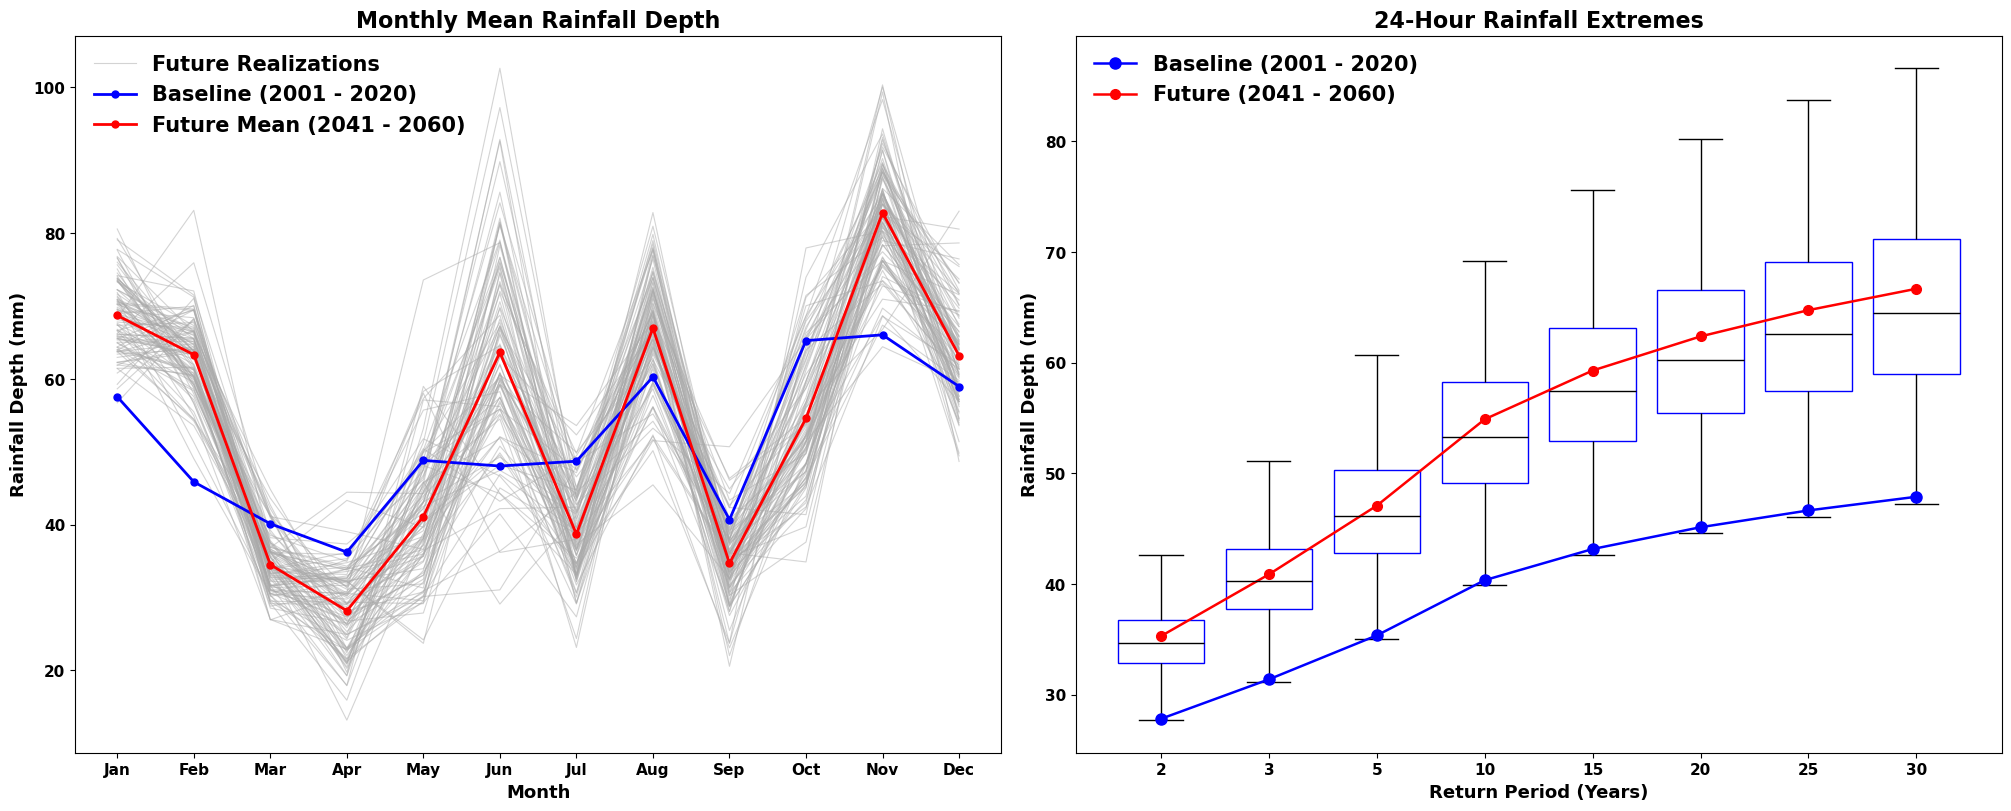

In [8]:

RPVAL_DF_OBS2 = RPVAL_DF_OBS.drop(['easting','northing'],axis=1)
month_names = [calendar.month_abbr[i] for i in range(1,13)]

if SIMULATION_MODE == 'future':
    fig, axes = plt.subplots(1, 2, figsize=(20,8),constrained_layout=True)
    axes = axes.flatten()
    plt.rcParams['font.weight'] = 'bold'
    def plot_stat(ax, x, real_df, obs, title, ylabel):
    
        real_lines = ax.plot(x,real_df[real_cols],color='darkgrey',linewidth=0.8,alpha=0.5)
        obs_line = ax.plot(x,obs,marker='o',color='blue',linewidth=2,markersize=5,label='Observed')
        real_mean = ax.plot(x,real_df.drop('Month',axis=1).mean(axis=1).to_numpy(),marker='o',color='red',linewidth=2,markersize=5)
        ax.set_title(title,fontsize=16,fontweight='bold')
        ax.set_xlabel('Month',fontsize=13,fontweight='bold')
        ax.set_ylabel(ylabel,fontsize=13,fontweight='bold')
        ax.set_xticks(range(1,13))
        ax.set_xticklabels(month_names,fontsize=11,fontweight='bold')
        ax.tick_params(axis='y',labelsize=11)
        plt.setp(ax.get_yticklabels(),fontweight='bold')
        ax.legend(handles=[real_lines[0], obs_line[0], real_mean[0]],labels=['Future Realizations', 'Baseline (2001 - 2020)','Future Mean '+'('+ str(StartYear) + ' - ' + str(StartYear+n_years-1) + ')'],fontsize=15,frameon=False)
    
    plot_stat(axes[0],monthly_mean_real['Month'],monthly_mean_real,obs_mean['value'],'Monthly Mean Rainfall Depth','Rainfall Depth (mm)')
    sns.boxplot(data=df_long,x='RP',y='Value',ax=axes[1],boxprops=dict(facecolor='none', edgecolor='blue'),medianprops=dict(color='black'),whiskerprops=dict(color='black'),
                capprops=dict(color='black'),showfliers=False,flierprops=dict(markeredgecolor='black'),patch_artist=True)
    
    
    x_obs = np.arange(len(RPVAL_DF_OBS2))
    x_future = np.arange(len(REAL_RP_MEAN))
    obs_line, = axes[1].plot(x_obs,RPVAL_DF_OBS2['RF'],'-o',color='blue',linewidth=1.8,markersize=8,label='Observed (2001 - 2020)')
    future_line, = axes[1].plot(x_future,REAL_RP_MEAN,'-o',color='red',linewidth=1.8,markersize=7,label='Future')
    axes[1].set_title('24-Hour Rainfall Extremes',fontsize=16,fontweight='bold')
    axes[1].set_xlabel('Return Period (Years)',fontsize=13,fontweight='bold')
    axes[1].set_ylabel('Rainfall Depth (mm)',fontsize=13,fontweight='bold')
    axes[1].tick_params(labelsize=11)
    plt.setp(axes[1].get_yticklabels(),fontweight='bold')
    plt.setp(axes[1].get_xticklabels(),fontweight='bold')
    axes[1].legend(handles=[obs_line, future_line],labels=['Baseline (2001 - 2020)', 'Future '+ '('+ str(StartYear) + ' - ' + str(StartYear+n_years-1) + ')'],fontsize=15,frameon=False,loc='upper left')
else:
    fig, axes = plt.subplots(1, 2, figsize=(20,8),constrained_layout=True)
    axes = axes.flatten()
    plt.rcParams['font.weight'] = 'bold'
    def plot_stat(ax, x, real_df, obs, title, ylabel):
        real_lines = ax.plot(x,real_df[real_cols],color='darkgrey',linewidth=0.8,alpha=0.5)
        obs_line = ax.plot(x,obs,marker='o',color='blue',linewidth=2,markersize=5,label='Observed')
        ax.set_title(title,fontsize=16,fontweight='bold')
        ax.set_xlabel('Month',fontsize=13,fontweight='bold')
        ax.set_ylabel(ylabel,fontsize=13,fontweight='bold')
        ax.set_xticks(range(1,13))
        ax.set_xticklabels(month_names,fontsize=11,fontweight='bold')
        ax.tick_params(axis='y',labelsize=11)
        plt.setp(ax.get_yticklabels(),fontweight='bold')
        ax.legend(handles=[real_lines[0], obs_line[0]],labels=['Realizations', 'Baseline (2001 - 2020)'],fontsize=15,frameon=False)
    
    plot_stat(axes[0],monthly_mean_real['Month'],monthly_mean_real,obs_mean['value'],'Monthly Mean Rainfall Depth','Rainfall Depth (mm)')
    sns.boxplot(data=df_long,x='RP',y='Value',ax=axes[1],boxprops=dict(facecolor='none', edgecolor='blue'),medianprops=dict(color='black'),whiskerprops=dict(color='black'),
                capprops=dict(color='black'),showfliers=False,flierprops=dict(markeredgecolor='black'),patch_artist=True)
    
    
    x_obs = np.arange(len(RPVAL_DF_OBS2))
    x_future = np.arange(len(REAL_RP_MEAN))
    obs_line, = axes[1].plot(x_obs,RPVAL_DF_OBS2['RF'],'-o',color='blue',linewidth=1.8,markersize=8,label='Observed (2001 - 2020)')
    WG_line, = axes[1].plot(x_future,REAL_RP_MEAN,'-o',color='red',linewidth=1.8,markersize=7,label='Future')
    axes[1].set_title('24-Hour Rainfall Extremes',fontsize=16,fontweight='bold')
    axes[1].set_xlabel('Return Period (Years)',fontsize=13,fontweight='bold')
    axes[1].set_ylabel('Rainfall Depth (mm)',fontsize=13,fontweight='bold')
    axes[1].tick_params(labelsize=11)
    plt.setp(axes[1].get_yticklabels(),fontweight='bold')
    plt.setp(axes[1].get_xticklabels(),fontweight='bold')
    axes[1].legend(handles=[obs_line, WG_line],labels=['Baseline (2001 - 2020)', 'Realization Mean (2001 - 2020)'],fontsize=15,frameon=False,loc='upper left')